In [4]:
import numpy as np, pandas as pd
from collections import defaultdict
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score

INTERIM = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim"
ARGNET_GENES = "/home/r4gbi/ARGNet/results/comparacion_genes_argnet.txt"
DEEPARG_GENES = f"{INTERIM}/deeparg_genes.mapping.ARG"

# 1) out-of-fold de tu modelo, agregado a nivel de gen
df = pd.read_csv(f"{INTERIM}/features_kmer4_fragmentado.csv")
df["gen"] = df["id"].str.split("__frag").str[0]
X = df.drop(columns=["id","etiqueta","gen"]).values; y = df["etiqueta"].values; g = df["gen"].values
oof = np.full(len(y), -1)
skf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
rng = np.random.default_rng(42)
for tr, va in skf.split(X, y, g):
    p = np.where(y[tr]==1)[0]; n = np.where(y[tr]==0)[0]
    bal = np.concatenate([p, rng.choice(n, size=len(p), replace=False)])
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
    rf.fit(X[tr][bal], y[tr][bal]); oof[va] = rf.predict(X[va])
por_gen = defaultdict(list)
for gid, pr in zip(df["gen"], oof): por_gen[gid].append(pr)
modelo_gen = {gid: (1 if any(v) else 0) for gid, v in por_gen.items()}

# 2) verdad
labels = pd.read_csv(f"{INTERIM}/muestra_genes_labels.tsv", sep="\t")
verdad = dict(zip(labels["id"], labels["etiqueta"]))

# 3) ARGNet
argnet_gen = {}
with open(ARGNET_GENES) as f:
    next(f)
    for line in f:
        p = line.rstrip("\n").split("\t")
        argnet_gen[p[0]] = 1 if p[1] == "ARG" else 0

# 4) DeepARG: read_id (columna 4) presente en el archivo = ARG
deeparg_pos = set()
with open(DEEPARG_GENES) as f:
    for line in f:
        if line.startswith("#"): continue
        cols = line.rstrip("\n").split("\t")
        if len(cols) > 3: deeparg_pos.add(cols[3])
deeparg_gen = {gid: (1 if gid in deeparg_pos else 0) for gid in labels["id"]}

# 5) evaluar los tres sobre los mismos genes
ids = [i for i in labels["id"] if i in argnet_gen and i in modelo_gen]
yt = [verdad[i] for i in ids]

def rep(nombre, yp):
    cm = confusion_matrix(yt, yp, labels=[0,1])
    print(f"\n=== {nombre} ===")
    print(f"  Real NEG   {cm[0,0]:>4}   {cm[0,1]:>4}")
    print(f"  Real POS   {cm[1,0]:>4}   {cm[1,1]:>4}")
    print(f"  Recall={recall_score(yt,yp):.3f}  Precision={precision_score(yt,yp,zero_division=0):.3f}  F1={f1_score(yt,yp):.3f}")

print(f"Genes comparados: {len(ids)}")
rep("ARGus (fragmenta + agrega)", [modelo_gen[i] for i in ids])
rep("ARGNet (gen completo)",          [argnet_gen[i] for i in ids])
rep("DeepARG (gen completo)",         [deeparg_gen[i] for i in ids])

/tmp/ipykernel_13793/343991416.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["gen"] = df["id"].str.split("__frag").str[0]


Genes comparados: 2000

=== ARGus (fragmenta + agrega) ===
  Real NEG    695    305
  Real POS    107    893
  Recall=0.893  Precision=0.745  F1=0.813

=== ARGNet (gen completo) ===
  Real NEG    912     88
  Real POS    447    553
  Recall=0.553  Precision=0.863  F1=0.674

=== DeepARG (gen completo) ===
  Real NEG    998      2
  Real POS    649    351
  Recall=0.351  Precision=0.994  F1=0.519


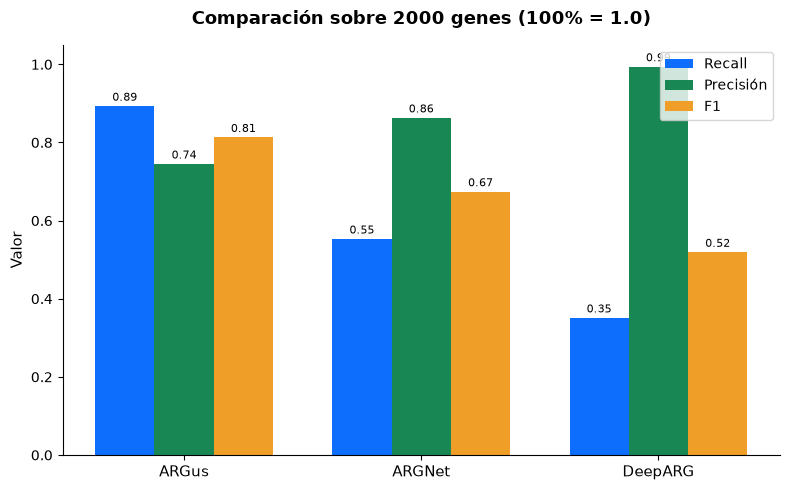

Gráfica guardada: comparacion_modelos.tiff


In [5]:
import matplotlib.pyplot as plt
import numpy as np

modelos = ["ARGus", "ARGNet", "DeepARG"]
recall    = [0.893, 0.553, 0.351]
precision = [0.745, 0.863, 0.994]
f1        = [0.813, 0.674, 0.519]

x = np.arange(3); w = 0.25
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
b1 = ax.bar(x - w, recall,    w, label="Recall",    color="#0D6EFD")
b2 = ax.bar(x,      precision, w, label="Precisión", color="#198754")
b3 = ax.bar(x + w,  f1,        w, label="F1",        color="#EF9F27")

ax.set_xticks(x); ax.set_xticklabels(modelos, fontsize=11)
ax.set_ylim(0, 1.05); ax.set_ylabel("Valor", fontsize=11)
ax.set_title("Comparación sobre 2000 genes (100% = 1.0)", fontsize=13, fontweight="bold", pad=15)
ax.legend(); ax.spines[['top','right']].set_visible(False)
for bars in (b1, b2, b3):
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
fig.tight_layout()
fig.savefig("/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/comparacion_modelos.tiff", dpi=300)
plt.show()
print("Gráfica guardada: comparacion_modelos.tiff")